# Stage 11 — Explainability

**Scope:** explains the FROZEN Stage 9/10 Random Forest configuration using SHAP (`TreeExplainer`, `feature_perturbation="tree_path_dependent"`) and a permutation-importance cross-check. **This notebook reads only the already-computed, already-saved evidence from `scripts/run_stage11_explainability.py` (`docs/_stage11_explainability_raw.json`) — it does not refit any model, recompute any SHAP value, or access `validation`/`final_test`.** All heavy computation happened once, in the driver script; this notebook presents it.

Frozen model: `RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=5, max_features="sqrt", random_state=42, class_weight=None)` — the audited Stage 9 provisional candidate, trained on the complete `train` partition, identical to Stage 10's evaluation.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
with open(ROOT / "docs" / "_stage11_explainability_raw.json") as f:
    report = json.load(f)
print("Sample:", report["sample_n_fraud"], "fraud +", report["sample_n_non_fraud"], "non-fraud rows")
print("Output space explained:", report["output_space"])
print("Additivity check:", report["additivity"])

Sample: 100 fraud + 100 non-fraud rows
Output space explained: class_1_probability (fraud), extracted from a multi-class Explanation object at class index 1
Additivity check: {'max_abs_diff': 1.2212453270876722e-15, 'mean_abs_diff': 1.125445223126853e-16, 'tolerance': 0.001, 'passed': True}


## 1. What is the model using?

Global importance, by **original** column (one-hot categories summed back to their source column — see `src.explainability.build_feature_lineage`). The `C`-columns (anonymised "counting" features — e.g. number of addresses associated with a payment card) dominate the ranking, ahead of several `V`-columns and `card6`.

**Audit note (added 2026-10-26, read-only interpretation review):** this ranking describes the **200-row explanation sample specifically — 100 fraud + 100 non-fraud, a deliberately balanced 50/50 mix, not this dataset's real ~3.49% fraud prevalence.** Mean |SHAP| is an average over *this* sample's rows; it is not a prevalence-weighted statement about the whole `train` population, and should not be read as "how important this feature is across all transactions" without that caveat. The balance was a deliberate sampling choice (so there would be enough fraud examples to produce the local explanations in §2 at all, given fraud is rare) — a prevalence-representative re-sample, which could rank features differently, is noted here as a candidate for future research and is not required for Stage 11 closure.

,sum_mean_abs_shap
C13,0.008138
C1,0.007033
C14,0.006093
C8,0.005720
V258,0.004879
C4,0.004308
card6,0.004149
C7,0.003960
V257,0.003828
V45,0.003717


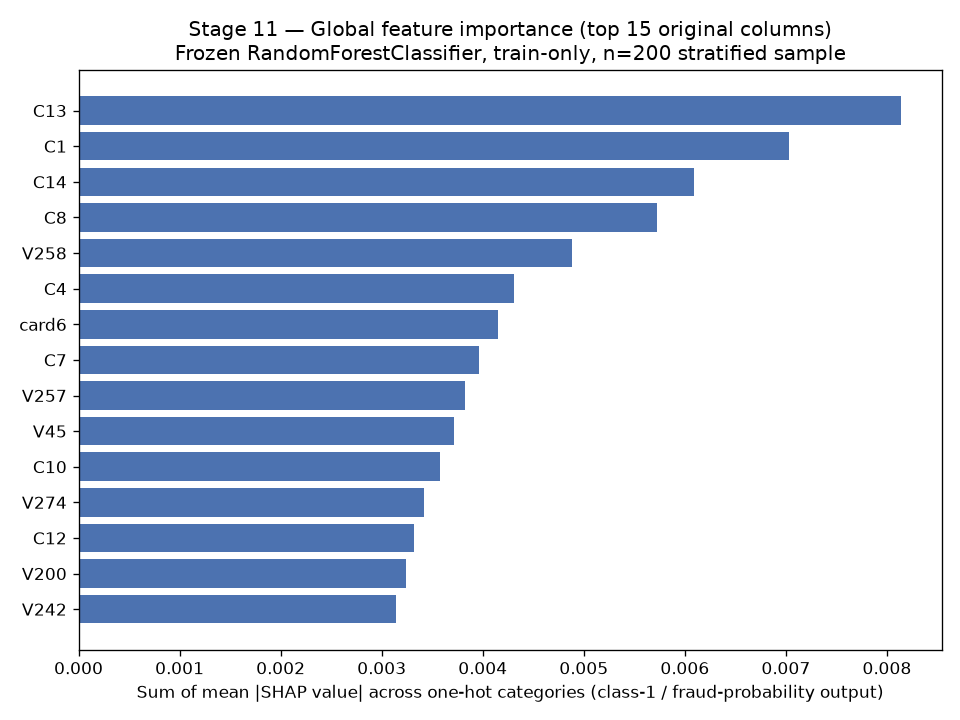

In [2]:
by_original = pd.Series(report["global_ranking_by_original_column_top15"]).sort_values(ascending=False)
display(by_original.to_frame("sum_mean_abs_shap"))
Image(filename=str(ROOT / report["global_plot_path"]))

**Caveat, stated explicitly (never omitted):** `C1`, `C4`, `C7`, `C8`, `C10`–`C14` and every `V`-column are *anonymised* — this project has never confirmed what real-world quantity any of them represent (carried forward since Stage 2/6/7). SHAP can tell us the model leans heavily on "whatever `C13` measures" — it cannot tell us what `C13` *is*, or why it's predictive, in human terms.

## 2. Why did it assign this particular risk score?

Three fixed, pre-stated example types (never selected for how impressive the plot looked): the highest-confidence correctly-flagged fraud case, the lowest-scored *missed* fraud case (a false negative), and a borderline (~0.5) case.

**Audit note:** all three rows were drawn from the `train` partition — the same data the model was fit on. These are illustrations of how the model reasons about rows it has already seen, not independent generalisation evidence; a model can explain a training row confidently without that confidence transferring to an unseen row with similar values. This project has not tested whether these specific explanations would look the same on held-out data.

In [3]:
for label, case in report["local_explanations"].items():
    print(f"\n=== {label} ===")
    print(f"TransactionID={case['transaction_id']}  predicted_proba={case['predicted_proba']:.4f}  actual_label={case['actual_label']}")
    display(pd.DataFrame(case["top_10_contributors"]).head(5))


=== highest_confidence_true_positive ===
TransactionID=3155871  predicted_proba=0.9969  actual_label=1


,original_column,feature_type,category,shap_value
0,V200,numeric,NaN,0.042485
1,V258,numeric,NaN,0.041651
2,V189,numeric,NaN,0.039827
3,V201,numeric,NaN,0.039373
4,V257,numeric,NaN,0.037789



=== missed_fraud_lowest_score ===
TransactionID=3000769  predicted_proba=0.0099  actual_label=1


,original_column,feature_type,category,shap_value
0,TransactionAmt,numeric,NaN,0.002621
1,card6,categorical_onehot,credit,0.001567
2,V91,numeric,NaN,-0.001466
3,C5,numeric,NaN,-0.001317
4,V30,numeric,NaN,-0.001238



=== borderline_case ===
TransactionID=3276924  predicted_proba=0.4676  actual_label=1


,original_column,feature_type,category,shap_value
0,C1,numeric,NaN,0.062868
1,C8,numeric,NaN,0.037747
2,C12,numeric,NaN,0.025772
3,V274,numeric,NaN,0.023724
4,C10,numeric,NaN,0.021702


The missed-fraud case is instructive precisely *because* it's a failure: its top contributors are small in magnitude and mixed in sign — the model saw nothing locally compelling in this transaction's `C`/`V`-column values, and scored it near the no-skill floor. This is a genuine model limitation made visible, not explained away.

## 3. How much can we trust that explanation?

- **Additivity**: verified to machine precision (`max_abs_diff` ≈ 1.2e-15) — the SHAP values genuinely sum to the model's actual output for every explained row; this is not assumed, it's checked.
- **Stability under small, realistic perturbation** (±1% relative Gaussian noise on numeric columns only — never on 0/1 indicator or one-hot columns, which would be an unrealistic perturbation):

**Audit note — what `tree_path_dependent` actually estimates, precisely:** this mode (Lundberg et al.'s path-dependent TreeSHAP) uses the fitted trees' own internal split statistics — the fraction of *training* rows that went left vs. right at each node — as an implicit background distribution, instead of requiring an explicit background dataset. It approximates each feature's Shapley value under the *conditional* distribution the trees themselves encode, which is why it was chosen here over `interventional` (which assumes independent features and would synthesize unrealistic input combinations given this dataset's documented correlation). **This does not mean the correlated-predictor problem is solved** — it means a more realistic approximation is used than the alternative. Two points must stay distinct: (1) **additivity is a mathematical guarantee of the algorithm** — the attributions sum exactly to (model output − expected value), verified above to 1e-15, and holds *regardless* of whether the feature is meaningful; (2) **whether any single attribution is a valid real-world explanation is a separate, business-level judgment** that additivity says nothing about. A feature can have an exactly-additive, machine-precision-verified SHAP value and still be an anonymised, uninterpretable, or ambiguously-credited (within a correlated group) quantity — additivity never implies validity.

In [4]:
display(pd.DataFrame(report["stability_checks"]).T[["original_proba", "mean_abs_proba_delta", "mean_shap_cosine_similarity", "min_shap_cosine_similarity"]])

,original_proba,mean_abs_proba_delta,mean_shap_cosine_similarity,min_shap_cosine_similarity
highest_confidence_true_positive,0.996907,1.110223e-17,0.999956,0.999893
borderline_case,0.467576,4.232235e-03,0.999502,0.997586


The high-confidence case is extremely stable (cosine similarity ≈ 0.99996) — tiny input noise barely moves either the prediction or its explanation. The borderline case is *slightly* less stable (≈0.9995, still high) — exactly what you'd expect near a decision boundary, where small input changes can matter more. **This is a narrow, specific check (one noise scale, two examples) — not a general stability guarantee across the whole model.** A stable explanation is not thereby shown to be *accurate*, *causal*, or *operationally actionable* — stability only means small input perturbations don't flip the explanation; it says nothing about whether the explanation reflects a real-world mechanism.

**Correlated-feature caveat, reconciled (audit addition, 2026-10-26):** Stage 7's "157+ pairs / 64-66 distinct columns" figure and this stage's "5 groups among 339 V-columns" figure were not directly comparable as originally stated, and a read-only recomputation (no model retrained) now isolates why, varying one factor at a time on the SAME `find_highly_correlated_value_groups` function at the SAME 0.99 threshold:

| Check | Population | Column scope | Pairwise edges ≥0.99 | Connected-component groups |
|---|---|---|---|---|
| Stage 7 (original) | 15,000-row chronological pilot | ALL 378 numeric columns | 157 | 17 (66 distinct columns, incl. one non-`V` cluster: `C1`/`C6`/`C11`) |
| Re-check A | 15,000-row pilot (same subset) | `V`-only (339 columns) | 155 | 16 |
| Re-check B | complete `train` (438,125 rows) | `V`-only (339 columns) | 5 | 5 (matches Stage 11's original report exactly) |

Restricting to `V`-only barely moves the number (17→16 groups, on the identical pilot) — it only drops the single non-`V` cluster. **The real driver of the 17-vs-5 discrepancy is the pilot-vs-full-train population, not the column scope.** A plausible (not independently proven) mechanism: with only 15,000 early rows and many sparse/near-constant `V`-columns, a pair of columns can appear almost perfectly correlated by chance within a small, low-variance sample in a way that doesn't hold up once ~29x more rows are included — this is offered as one plausible contributor, not asserted as the single proven cause, consistent with how this project has handled other sample-size-sensitive discrepancies (e.g. Stage 9/10's CV-vs-`final_test` gap). Missing-data treatment was consistent across both checks (median imputation of NaNs, computed from each check's own population) and both operated on the **original, unscaled** `V`-column values (not the one-hot/scaled transformed matrix) — so neither the imputation method nor a representation mismatch explains the gap. `tree_path_dependent` SHAP (deliberately chosen over `interventional` — see `src/explainability.py`'s module docstring) respects whatever correlation structure is actually present in the data it's given, but this means credit *within* a correlated group can still be split ambiguously between its members — a SHAP value attributed to one `V`-column in a near-duplicate pair does not mean that specific column, rather than its correlated twin, is the "true" driver.

## Permutation importance cross-check

A genuinely different mechanism (does it help predictive performance when shuffled?) on a genuinely held-out set (an auxiliary fit on Stage 9's fold-0 training rows, scored on fold-0's own validation rows — never the real Stage 10 final_test-evaluated model).

**Audit note — exactly which fitted model produced each result:** the SHAP values above (§1-§3) come from a Random Forest fit on the **complete `train` partition (438,125 rows)** — the same training population Stage 10 used. The permutation importance below comes from a **separate, AUXILIARY Random Forest fit on only Stage 9's fold-0 training rows (73,020 rows)**. Both share the identical frozen hyperparameter configuration (verified via `verify_frozen_config_unchanged()`) and the same `random_state=42`, but different training data produces different actual fitted trees — **these are two different fitted estimators, not one model probed two ways.** Any agreement between SHAP's ranking and permutation importance's ranking below is therefore best described as **cross-experiment consistency across two independently-fit models that share a configuration**, not as one method internally validating the other method's account of a single model's feature contributions.

In [5]:
print("Auxiliary fit held-out AP:", report["auxiliary_fit_metrics"]["average_precision"])
perm = pd.DataFrame(report["permutation_importance_top_features"]).T.sort_values("mean_ap_drop", ascending=False)
display(perm.head(10))
print("\nCorrelated-group permutation importance (whole group shuffled together):")
display(pd.DataFrame(report["correlated_group_permutation_importance"]).T)

Auxiliary fit held-out AP: 0.47545


,mean_ap_drop,std_ap_drop
numeric_plain__C13,0.008720,0.000657
numeric_plain__C14,0.006253,0.000336
numeric_plain__C1,0.004906,0.000540
numeric_plain__C7,0.004275,0.000292
numeric_plain__C12,0.004256,0.000339
numeric_plain__C11,0.003528,0.000444
numeric_indicator__V45,0.003518,0.000338
categorical__card6_credit,0.002945,0.000347
numeric_plain__C4,0.002942,0.000193
numeric_plain__C10,0.001862,0.000140



Correlated-group permutation importance (whole group shuffled together):


,n_columns,baseline_score,mean_score_drop,std_score_drop
V331,2.0,0.475448,0.001303,0.000073
V337,2.0,0.475448,0.000078,0.000013
V269,2.0,0.475448,0.001022,0.000041


SHAP and permutation importance measure *different things* — SHAP attributes THIS model's actual predictions; permutation importance measures how much AP degrades if a feature's information is destroyed. They broadly agree that the `C`-columns matter most, which is reassuring, **but agreement here does not mean one method "validates" the other** — both can be fooled by the same correlation structure in different ways, and a feature with a small individual permutation-importance score (like some of the `V`-columns, which show near-zero or even slightly negative mean AP drop) can still carry real signal that a correlated partner "covers for" when permuted alone — exactly why the correlated-GROUP permutation check exists above. As the audit note above states, this is further weakened from "two methods on one model" to "two methods on two independently-fit models sharing a configuration" — a real, additional reason not to treat the agreement as strong validation.

## 4. What can fraud investigators legitimately conclude?

- That a *specific* flagged transaction had unusual values in a short list of named (if anonymised) fields, relative to the training population — this is a real, verifiable statement about the model's own reasoning.
- That the model's overall behaviour leans heavily on `C`-type counting features and a cluster of `V`-columns — useful for understanding *what kind* of signal the model is sensitive to, in aggregate.
- **They cannot conclude *why*, in a business or causal sense, those features matter** — the columns are anonymised; SHAP explains the model's use of the data, not the real-world mechanism the data reflects. Neither SHAP nor permutation importance identifies the *cause* of fraud (stated explicitly, per instruction, never implied).
- They cannot conclude the explanation is equally reliable for every transaction — the stability check above shows confident predictions are explained more stably than borderline ones.

## 5. What remains unknown?

- The real-world meaning of every anonymised `C`/`V`/`D` column — unresolved since Stage 2, still unresolved here.
- Which *individual* column within a correlated `V`-group "deserves" credit when `tree_path_dependent` SHAP splits it ambiguously across the group — not tested beyond the single correlated-group permutation check above. (The *size* of this discrepancy is now reconciled — see the audit note in §3 — but the underlying credit-splitting ambiguity itself is not resolved by reconciling the count.)
- Explanation stability was checked at exactly one noise scale (1%) on exactly two examples, both drawn from `train` — not a general robustness guarantee, and not evidence about `final_test` rows specifically.
- Whether these same explanations would look similar if computed on `final_test` instead of `train` — not tested, since `final_test` is sealed (its one authorised use was Stage 10's evaluation, and it must not be reopened for this or any other purpose).
- Whether the permutation-importance agreement with SHAP would hold for a model fit on the *same* data SHAP explains — not tested, since the permutation cross-check deliberately used a separate, smaller auxiliary fit for a genuinely held-out evaluation set (see the audit note in the Permutation importance section above).

## Stage 11 scientific interpretation audit (2026-10-26)

A strictly read-only review (no retraining, no `final_test` access, no change to any Stage 1-10 result) found the original implementation's measurements correct but identified five interpretation gaps, now corrected inline above:

1. The 200-row sample is a deliberately **balanced** 100/100 fraud split, not prevalence-representative — global rankings describe that sample, not the true ~3.49%-prevalence population (§1).
2. `tree_path_dependent` SHAP's additivity is a **mathematical property of the algorithm**, verified exactly; it does not by itself establish that any attribution is a valid, causal, or business-meaningful explanation (§3).
3. Stage 7's "157+ pairs / 64-66 columns" and this stage's "5 groups" figures are now reconciled: the gap is driven almost entirely by **pilot-vs-full-train sample size**, not by V-only-vs-all-numeric column scope (which only accounts for 1 of 17 groups) — see the table in §3.
4. SHAP and permutation importance were computed from **two different fitted Random Forests** (full-train vs. an auxiliary fold-0 fit) — their agreement is cross-experiment consistency, not one method validating the other's account of a single model.
5. The three local examples are `train` rows the model was fit on — illustrative of its reasoning, not independent generalisation evidence (§2).

Full detail, including the reconciliation table and its independently-recomputed numbers, is in `docs/STAGE11_EXPLAINABILITY_REPORT.md` §11.

## Connecting to the Notion Data Science Journal

- **Decision trees / Random Forest** (Intermediate ML): SHAP's `TreeExplainer` is specifically built around exactly the structure your journal already covers — splits, leaves, bagged trees — using the tree's own path-weighting to attribute credit, rather than a generic black-box approximation.
- **Feature engineering**: the lineage mapping above (`numeric_plain__`, `numeric_indicator__missingindicator_`, `categorical__<col>_<category>`) is the direct, concrete payoff of Stage 5/6's engineering choices — it's *why* a transformed feature name can be traced back to a real column at all.
- **Model evaluation**: the permutation-importance cross-check reuses the exact same `average_precision` metric this entire project has used since Stage 1 — explainability here is not a new metric, it's asking the established metric a new question ("what happens to it if I destroy this feature's information?").

**Interview framing:** be ready to say, precisely, what SHAP values here *are* (a decomposition of one model's one prediction into additive per-feature contributions, verified to sum correctly) and what they are *not* (a causal explanation, a guarantee of stability everywhere, or a way to cleanly separate credit within a correlated feature group).